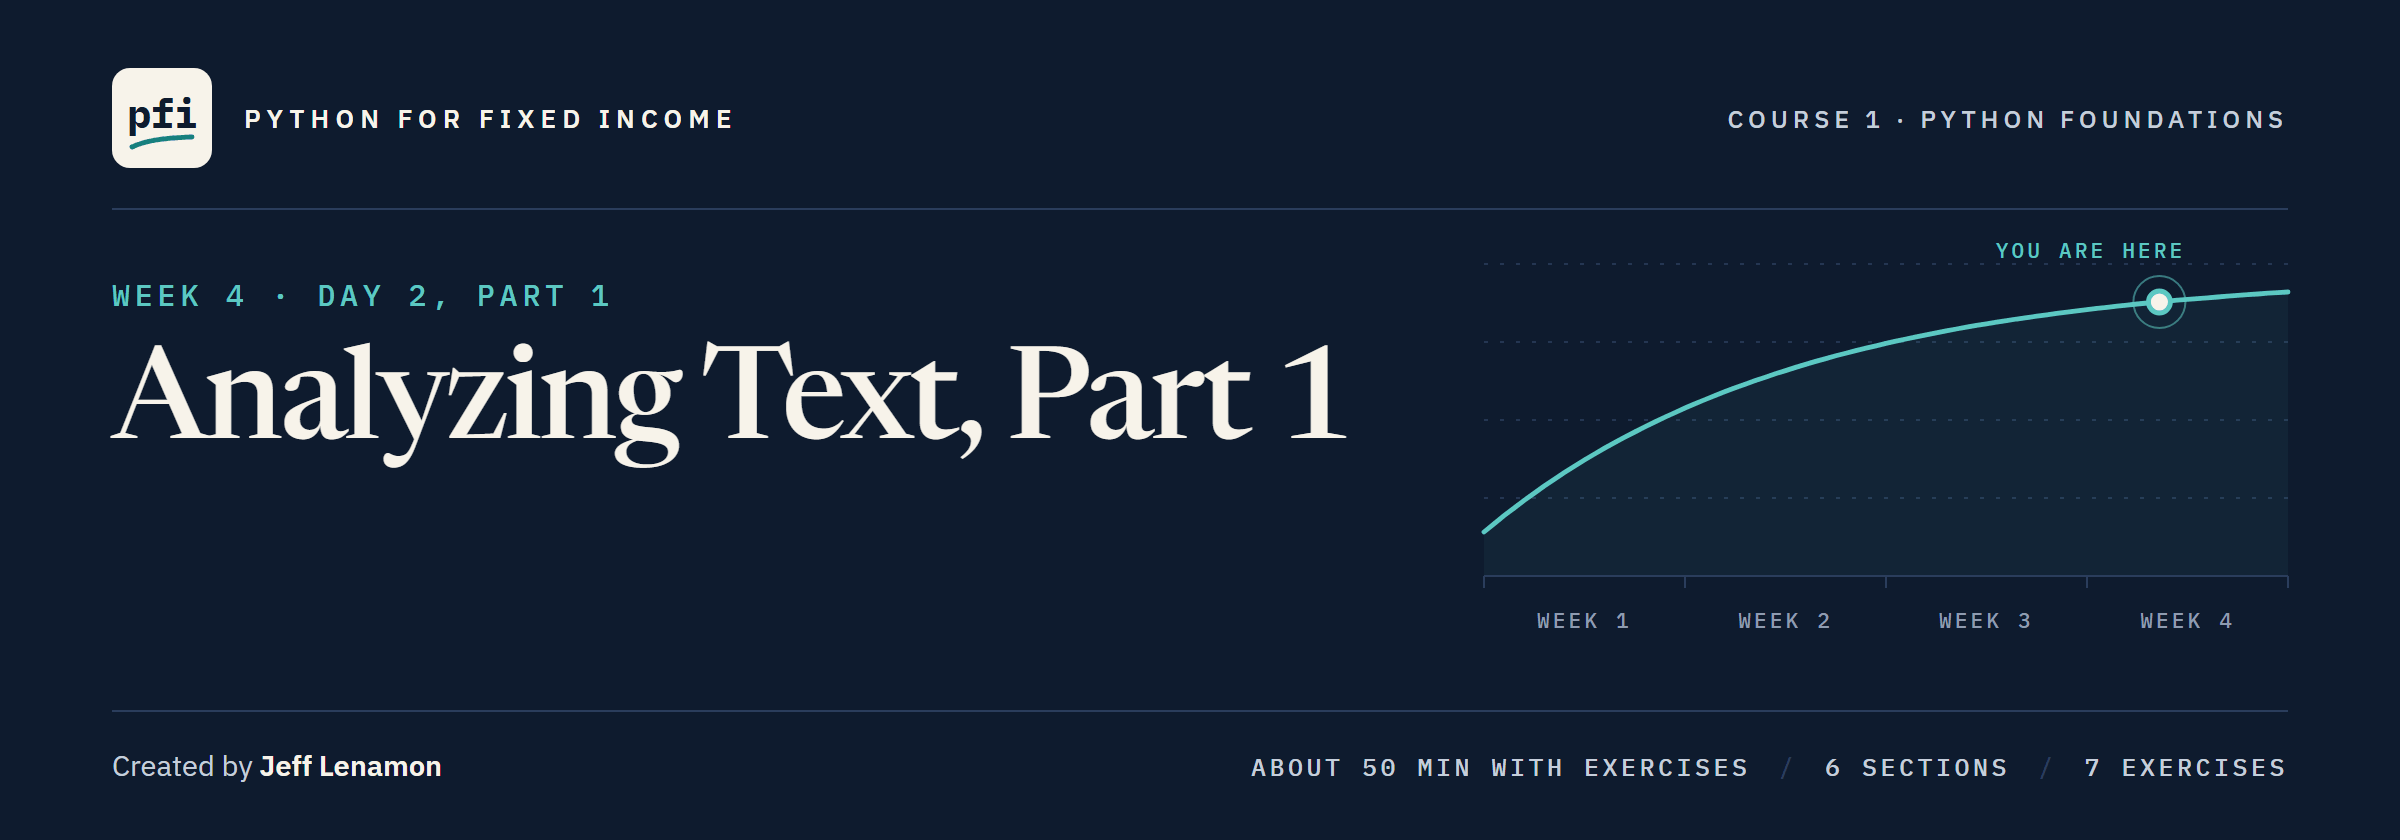

# Analyzing Text, Part 1

Week 4, Day 2, Part 1. Text is data too. Take one published statement as a Python string, pull figures out of it with patterns, and take a bond description apart.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day2/17_analyzing_text.ipynb)

## The Desk Lead's Note

> We keep every FOMC statement and have only ever read them. Before we run all 46, prove the tools on one, 2023-11-01: what figures does it state, how often does it say "rate", the word, and who voted? I can count the names myself, so your count must agree with mine. Then our own book: the broker sends bond descriptions as one line of text, and I want a table; and every CUSIP in the holdings file must have the right shape. Counts only: no reading of policy.

<table align="left">
<tr><th align="left">The statements</th><th align="left"></th></tr>
<tr><td align="left">Source</td><td align="left">Board of Governors of the Federal Reserve System, each statement from its press release: https://www.federalreserve.gov/monetarypolicy/fomccalendars.htm</td></tr>
<tr><td align="left">Retrieved</td><td align="left">2026-10-03</td></tr>
<tr><td align="left">Span</td><td align="left">46, 2021-01-27 to 2026-09-16, every scheduled meeting</td></tr>
<tr><td align="left">Reuse</td><td align="left">Public domain, citing the Board as the source: https://www.federalreserve.gov/disclaimer.htm</td></tr>
<tr><td align="left">Changes</td><td align="left">White space only</td></tr>
</table>
<br clear="left">

The descriptions and CUSIPs come from the course's holdings file; the issuers are invented.

**Five asks: the figures, the word rate, the voters, the descriptions, the CUSIPs.**

## Your Route Through Day 2, Part 1

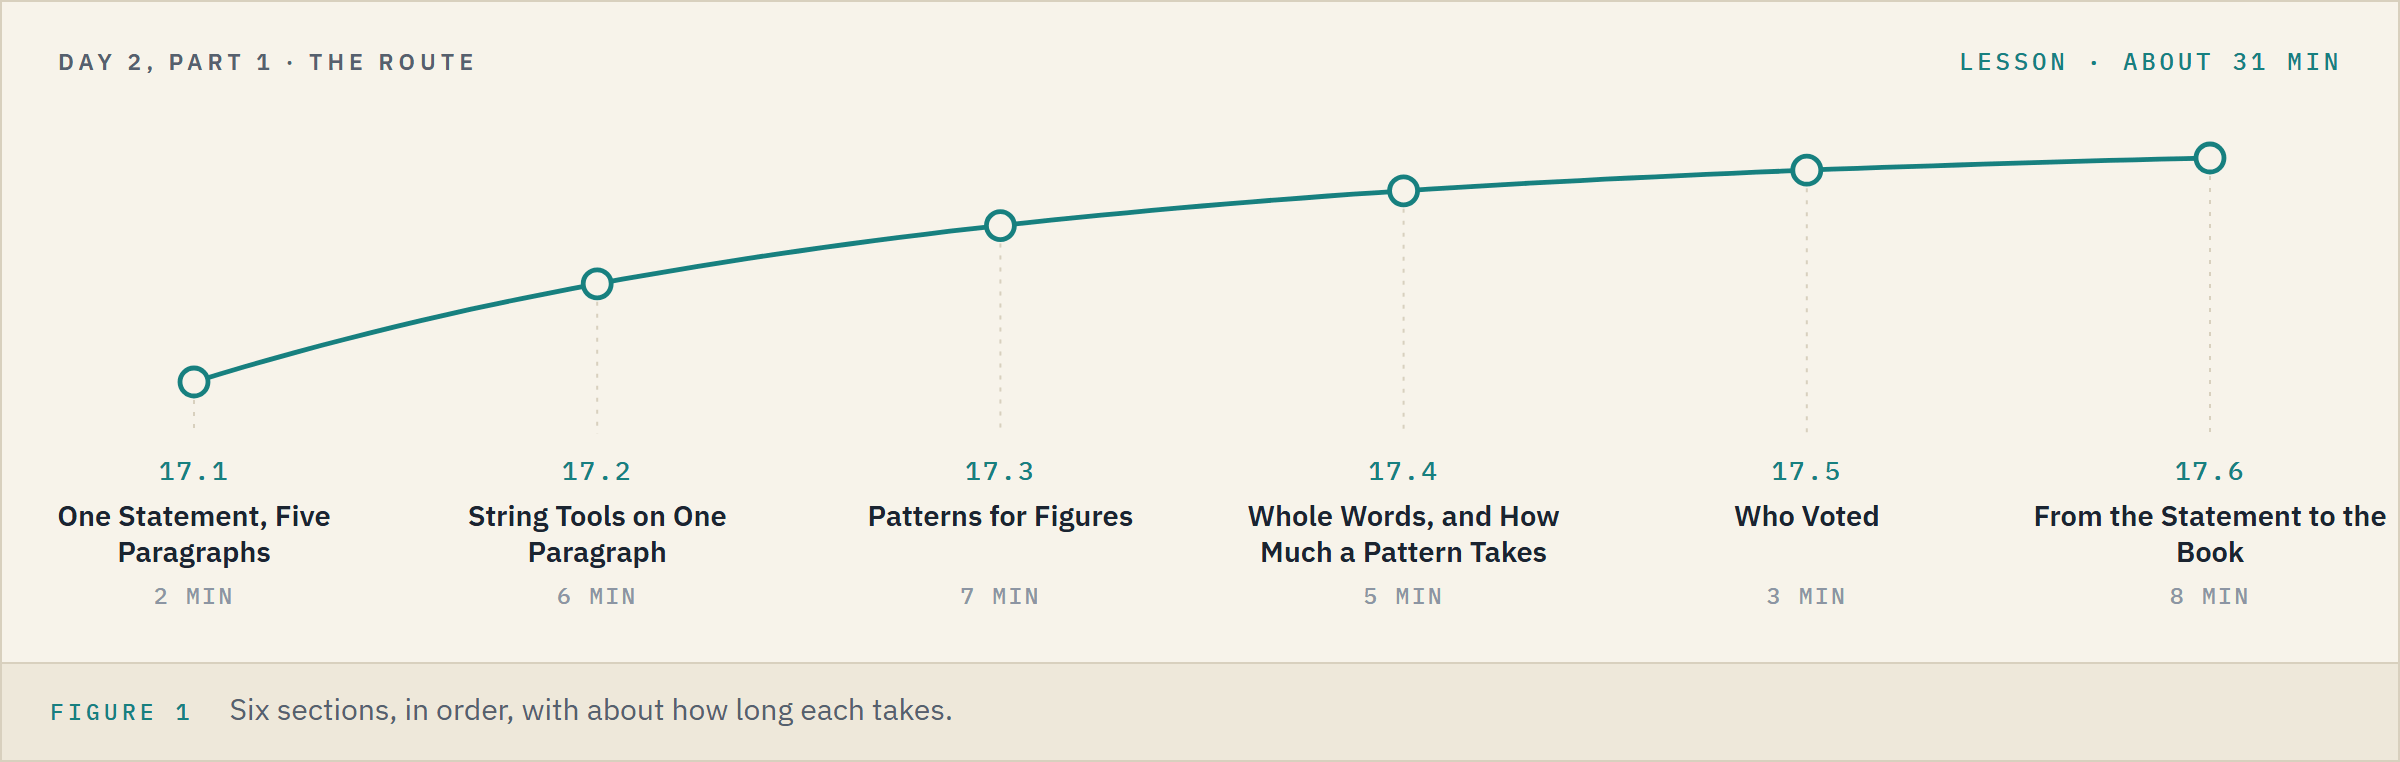

**Time.** About 31 minutes for the lesson, then about 21 for the seven exercises.

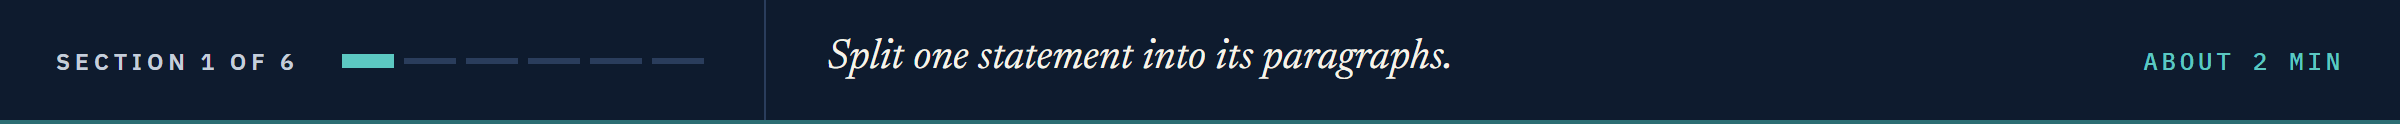

## 17.1 One Statement, Five Paragraphs

### Load the Statements

Q. Load the statements. What do they span, and is any missing or in twice?

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in the Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
# the repo's data folder on your machine; in Colab, GitHub
if os.path.exists('../../../data/fomc_statements.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
statements = pd.read_csv(data_folder + 'fomc_statements.csv')
print(statements.shape, statements['date'].min(), statements['date'].max())
# the first case study's checks: gaps, repeated rows, a column with no value twice
gaps, repeats = statements.isna().sum().sum(), statements.duplicated().sum()
print(gaps, repeats, statements['text'].is_unique)

(46, 3) 2021-01-27 2026-09-16
0 0 True


No gaps, no repeats: a statement in twice would double every count.

### One Statement as a String

Q. Take out the statement of 2023-11-01 and cut it into paragraphs.

In [2]:
# the row of that date, its text column, and the one value in it
statement = statements.loc[statements['date'] == '2023-11-01', 'text'].iloc[0]
# a line break, written '\n', separates the paragraphs
paragraphs = statement.split('\n')
print(type(statement), len(paragraphs))
opening = paragraphs[0]
print(opening)

<class 'str'> 5
Recent indicators suggest that economic activity expanded at a strong pace in the third quarter. Job gains have moderated since earlier in the year but remain strong, and the unemployment rate has remained low. Inflation remains elevated.


A `str`, like Day 1's tickers, only longer.
`'\n'` is Day 2's line break, the one that broke a typed path.

### The Statement's Shape

Q. How long is each paragraph? Draw it.

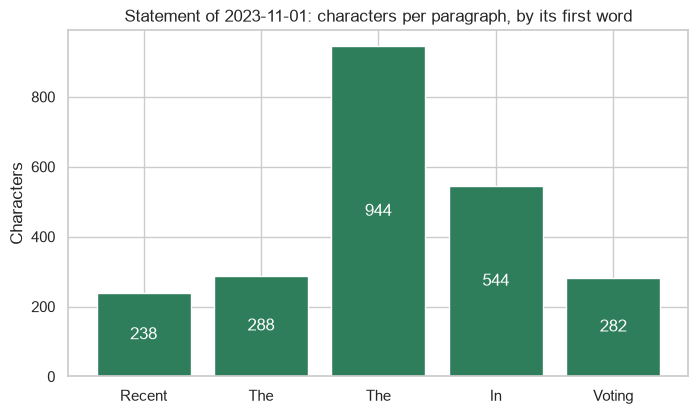

In [3]:
# len() and the first word of each paragraph, in comprehensions as in Day 1 Part 2
lengths = [len(paragraph) for paragraph in paragraphs]
first_words = [paragraph.split()[0] for paragraph in paragraphs]
fig, ax = plt.subplots(figsize=(8, 4.5))
# tick_label= names each bar, even two the same; label_type='center' puts each count inside
bars = ax.bar([1, 2, 3, 4, 5], lengths, tick_label=first_words)
ax.bar_label(bars, label_type='center', color='white')
ax.set_title('Statement of 2023-11-01: characters per paragraph, by its first word')
ax.set_ylabel('Characters')
plt.show()

The third paragraph, 944 characters, is the longest; the last, `Voting`, lists names.

**Figures in the third, voters in the last. Start with the first.**

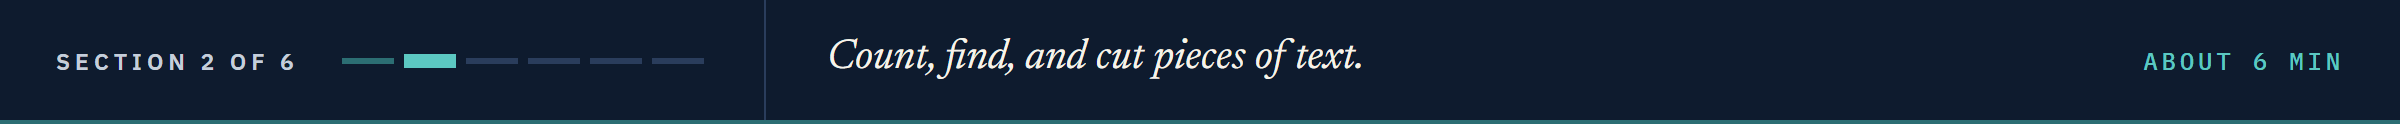

## 17.2 String Tools on One Paragraph

### How Long, and Is It There

Day 1's string methods work the same on a paragraph.

Q. How long are the paragraph and the statement? Is `inflation` in the paragraph?

In [4]:
# len() counts every character, spaces and punctuation too
print(len(opening), len(statement))
# in tells capitals from lower case; lower() first ignores them
print('inflation' in opening, 'inflation' in opening.lower())

238 2300
False True


The paragraph runs 238 characters and the statement 2,300.
`False`, then `True`: the paragraph says `Inflation`, Day 1's `'energy' in issuer` trap.

### Where a Word Starts

Q. Where does `Inflation` start?

In [5]:
# find() gives the position of the first match, counting from 0
position = opening.find('Inflation')
print(position)
# Day 1's slices: from the start, from the position, from the end
print(opening[:6], opening[position:position + 9], opening[-9:])

211
Recent Inflation elevated.


211: Python counts from 0, as Day 1's positions picture showed, so it is the 212th character.

### Counting `rate`

**Predict 1**

Q. In the paragraph printed in 17.1, the word rate appears once: `the unemployment rate`. What does `opening.count('rate')` return? Write down a number.

In [6]:
# count() counts how many times a piece of text appears
print(opening.count('rate'))
print(opening.count('remain'))

2
3


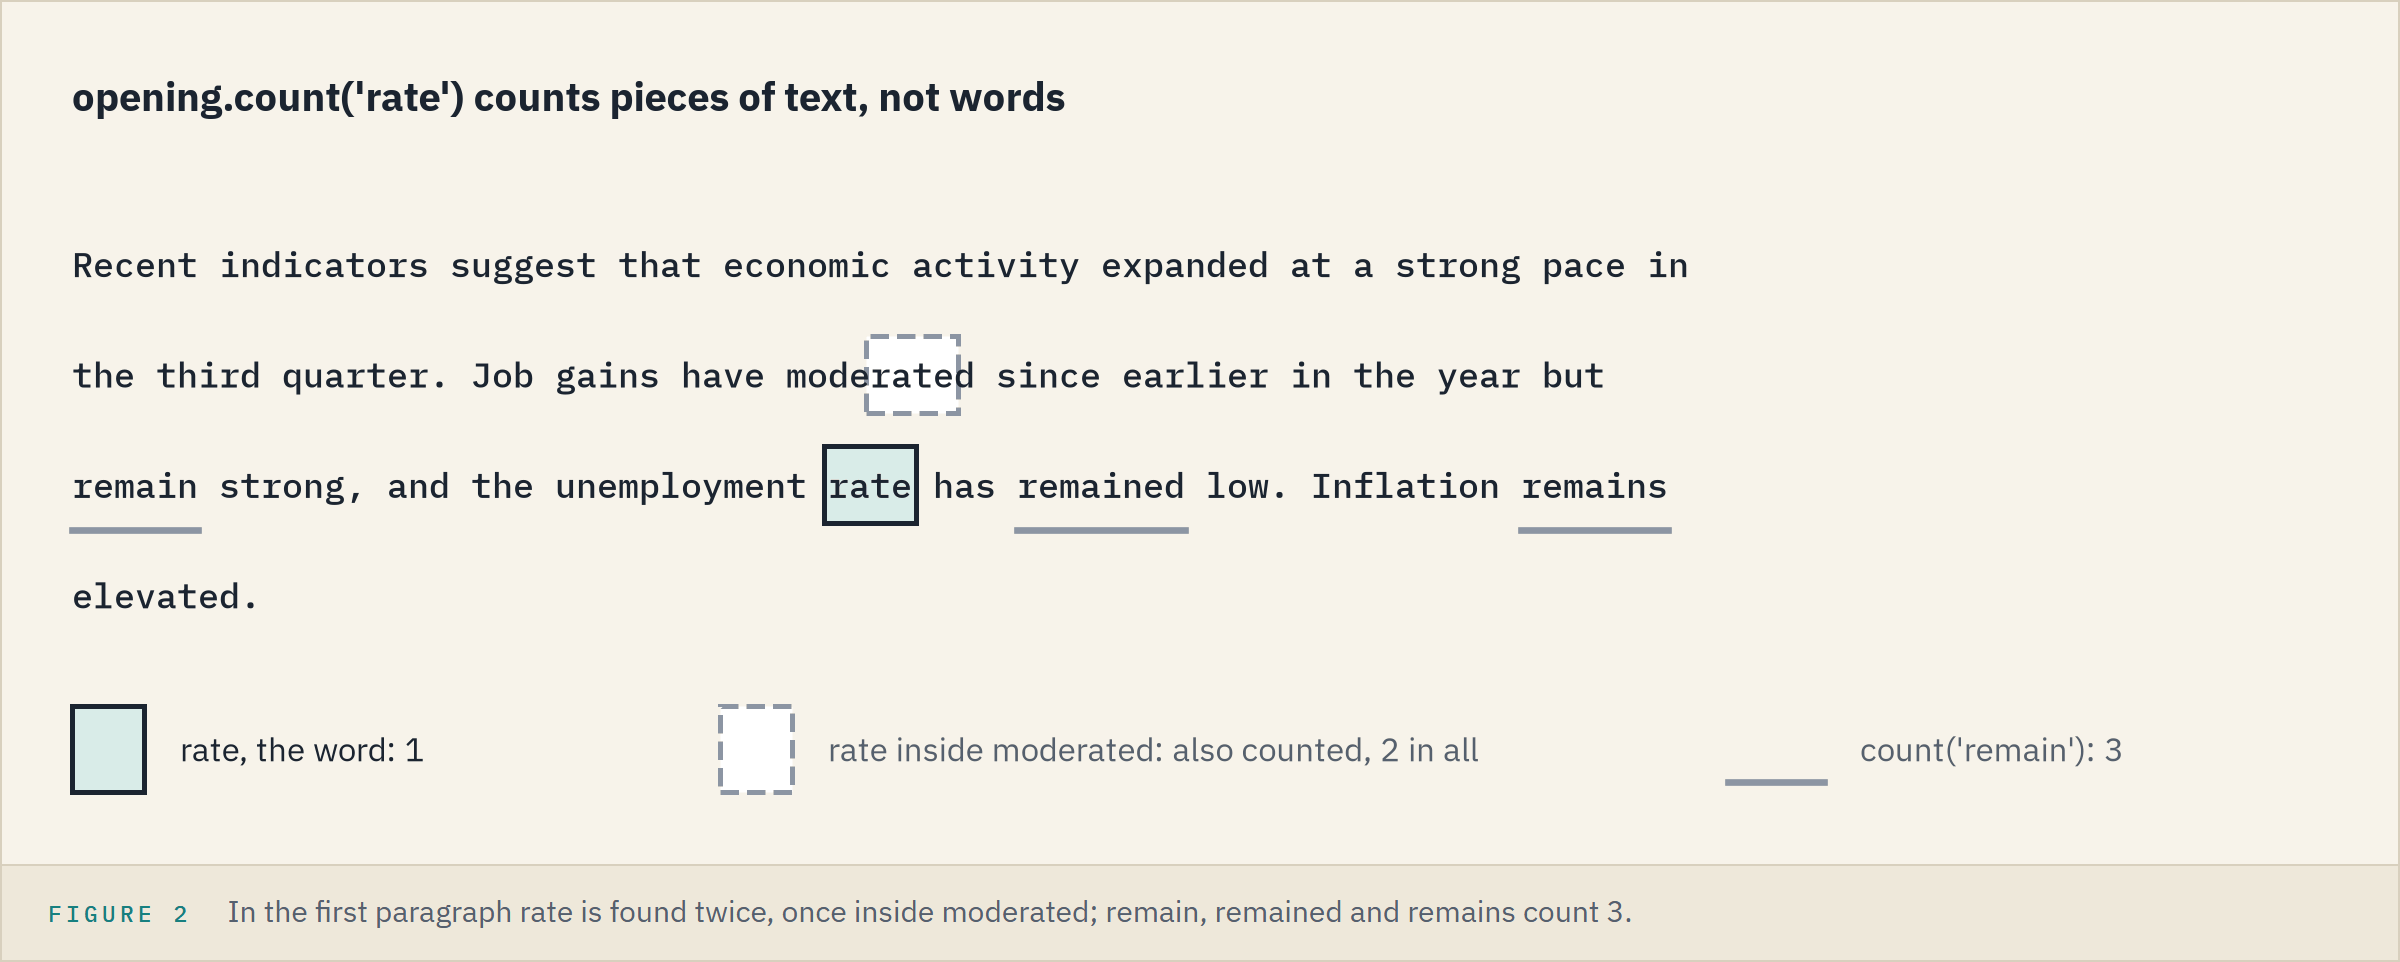

2: the second sits inside `moderated`.
`remain` counts 3: `remain`, `remained`, and `remains`.

**`count()` counts pieces of text, not words.**

### Words and Sentences

Q. Split the paragraph into words. How many are there?

In [7]:
# split() cuts at every run of spaces and hands back a list
words = opening.split()
print(len(words), words[-3:])

37 ['Inflation', 'remains', 'elevated.']


37 words, and `'elevated.'` keeps its full stop: `split()` cuts at spaces and nothing else.

Q. Join the first five words back together.

In [8]:
# join() is split() in reverse: the string in front goes between the items
print(' '.join(words[:5]))
print('-'.join(words[:5]))

Recent indicators suggest that economic
Recent-indicators-suggest-that-economic


Q. Cut the paragraph at each full stop.

In [9]:
# split('.') cuts at every full stop
pieces = opening.split('.')
# repr() prints a string with its quotes, so a space at either end shows
for piece in pieces:
    print(repr(piece))

'Recent indicators suggest that economic activity expanded at a strong pace in the third quarter'
' Job gains have moderated since earlier in the year but remain strong, and the unemployment rate has remained low'
' Inflation remains elevated'
''


Two pieces start with a space, and the last is empty: what follows the final full stop.

Q. Strip the spaces and drop the empty piece.

In [10]:
# Day 1's strip() on each piece; the if keeps a piece only when something is left
sentences = [piece.strip() for piece in pieces if piece.strip() != '']
print(len(sentences), sentences[2])

3 Inflation remains elevated


The paragraph holds 3 sentences.
A full stop is a rough cut: the next paragraph's `U.S.` would fall apart.

**Excel side by side.** The paragraph in A2:

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Where a word starts</td><td align="left"><code>opening.find('Inflation')</code></td><td align="left"><code>=FIND("Inflation", A2)</code>, then <code>=MID(A2, 212, 9)</code></td><td align="left">211 against 212: Excel counts from 1</td></tr>
<tr><td align="left">Is it there</td><td align="left"><code>'inflation' in opening</code></td><td align="left"><code>=ISNUMBER(FIND("inflation", A2))</code>; <code>SEARCH</code> ignores capitals</td><td align="left">FALSE; TRUE with <code>SEARCH</code></td></tr>
<tr><td align="left">Count a piece</td><td align="left"><code>opening.count('rate')</code></td><td align="left"><code>=(LEN(A2)-LEN(SUBSTITUTE(A2, "rate", "")))/LEN("rate")</code></td><td align="left">2</td></tr>
<tr><td align="left">Count the words</td><td align="left"><code>len(opening.split())</code></td><td align="left"><code>=COUNTA(TEXTSPLIT(A2, " "))</code>; any version: <code>=LEN(TRIM(A2))-LEN(SUBSTITUTE(TRIM(A2), " ", ""))+1</code></td><td align="left">37</td></tr>
</table>
<br clear="left">

`TEXTSPLIT` is in Microsoft 365 and Excel 2024; Text to Columns splits by hand.

**Every tool here looks for one exact piece of text. A figure changes its digits every meeting.**

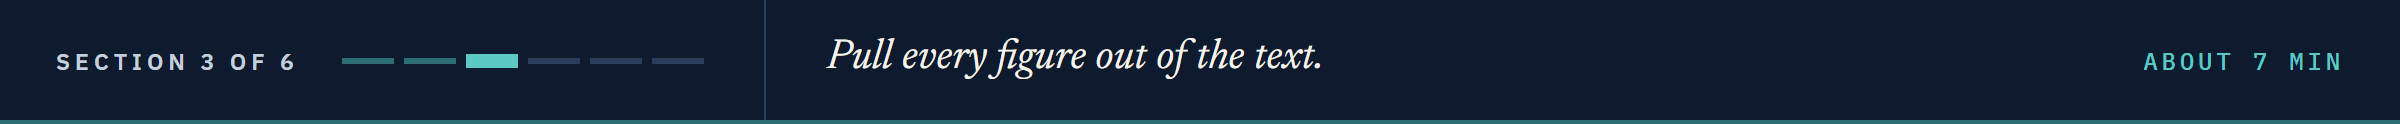

## 17.3 Patterns for Figures

### A Shape, Not a Text

`2 percent` and `5-1/4 to 5-1/2 percent` share a shape: digits, then percent.
A **regular expression**, or regex, writes a shape down.
Python's `re` module has `re.findall()` for every match, `re.search()` for the first, and `re.sub()` to replace.

Q. Take the third paragraph. How long is it, and what are its first two sentences?

In [11]:
# re comes with Python: nothing to install
import re

policy = paragraphs[2]
# no abbreviations here, so a full stop and a space end each sentence
policy_sentences = policy.split('. ')
print(len(policy), len(policy_sentences))
print(policy_sentences[0] + '.')
print(policy_sentences[1] + '.')

944 6
The Committee seeks to achieve maximum employment and inflation at the rate of 2 percent over the longer run.
In support of these goals, the Committee decided to maintain the target range for the federal funds rate at 5-1/4 to 5-1/2 percent.


The third paragraph runs 944 characters in 6 sentences.

### Plain Text and Digits

Q. Find every `percent` in the paragraph, then every digit.

In [12]:
# plain text is the simplest pattern: it matches itself
print(re.findall('percent', policy))
# \d is any one digit; \d+ is one or more digits in a row
print(re.findall(r'\d', policy))
print(re.findall(r'\d+', policy))

['percent', 'percent', 'percent', 'percent']
['2', '5', '1', '4', '5', '1', '2', '2', '2']
['2', '5', '1', '4', '5', '1', '2', '2', '2']


9 digits, the same list both ways: no figure here has two digits in a row.
The `r` makes a **raw string**, where a backslash stays a backslash: write every pattern as `r'...'`.

### Digits Before `percent`

**Predict 2**

Q. Read to its end, the paragraph says `2 percent` three times. How many matches does `re.findall(r'\d+ percent', policy)` return? Write down a number.

In [13]:
# one or more digits, a space, and the word percent
print(re.findall(r'\d+ percent', policy))

['2 percent', '2 percent', '2 percent', '2 percent']


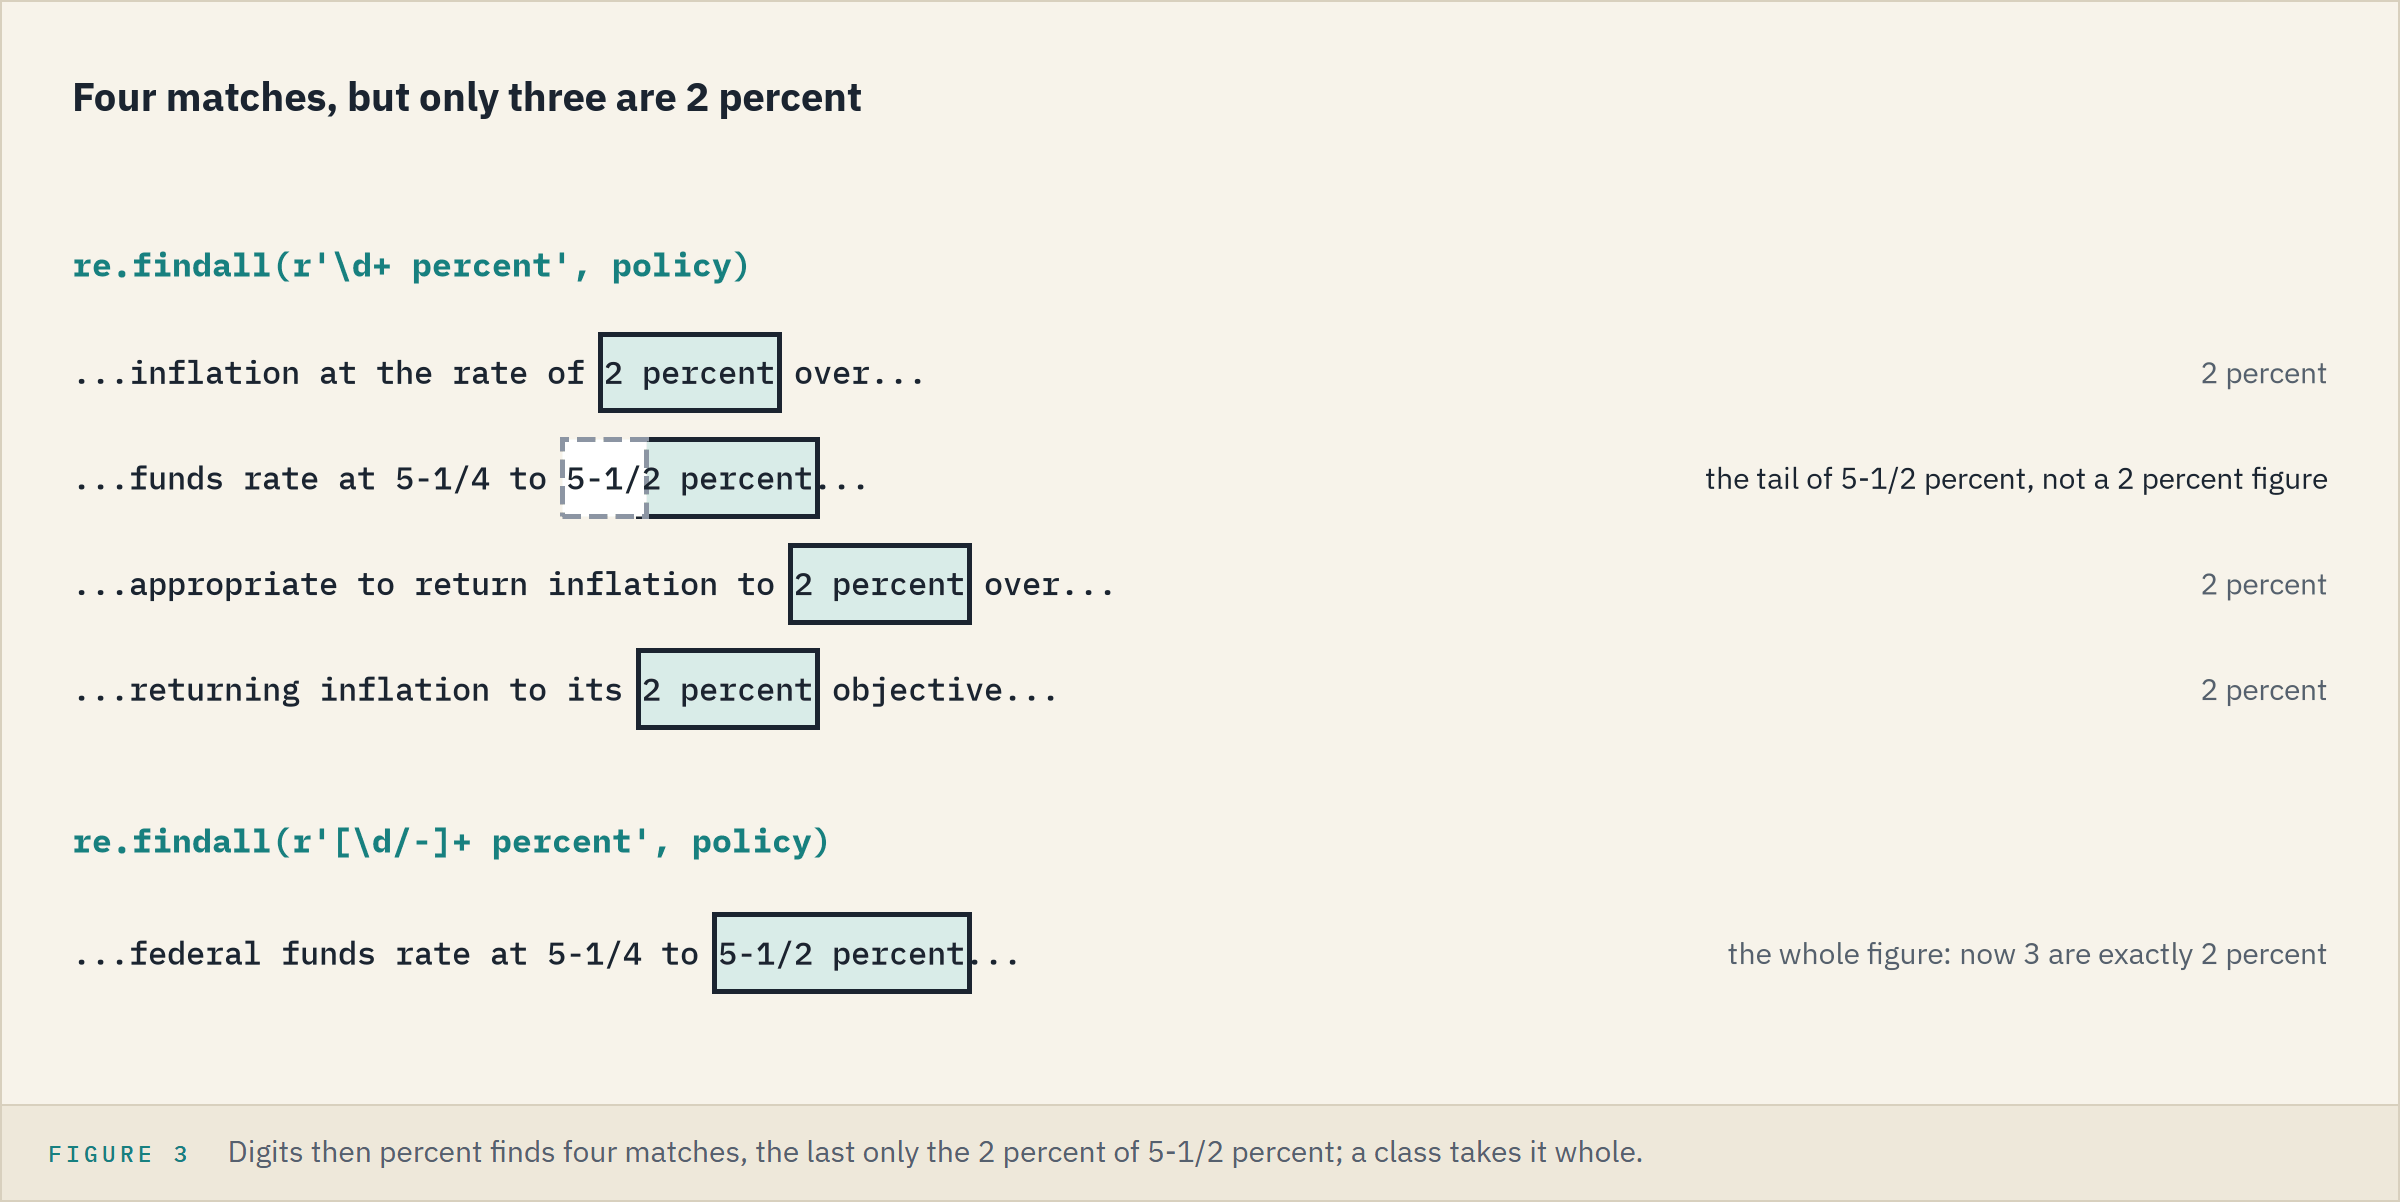

4, and every one reads `2 percent`.
The fourth is the tail of `5-1/2 percent`: the pattern **matched too much**.

**Print what a pattern matched before trusting how many.**

### A Class of Characters

Q. Match the whole figure: digits, slashes, and hyphens, then `percent`.

In [14]:
# square brackets list the characters allowed at one spot; + repeats it
figures = re.findall(r'[\d/-]+ percent', policy)
print(figures)
print(figures.count('2 percent'))

['2 percent', '5-1/2 percent', '2 percent', '2 percent']
3


4 figures, 3 of them exactly `2 percent`: the text's own count.

<table align="left">
<tr><th align="left">Piece</th><th align="left">Means</th></tr>
<tr><td align="left"><code>[a-z]</code></td><td align="left">one lower-case letter: a hyphen between two is a range</td></tr>
<tr><td align="left"><code>[\d/-]</code></td><td align="left">a digit, a slash, or a hyphen, plain when last</td></tr>
<tr><td align="left"><code>[^abc]</code></td><td align="left">one character that is not a, b, or c</td></tr>
</table>
<br clear="left">

Q. Find the range, written as the statement writes it.

In [15]:
# a figure, the word to, a figure, then percent
range_pattern = r'[\d/-]+ to [\d/-]+ percent'
print(re.findall(range_pattern, policy))

['5-1/4 to 5-1/2 percent']


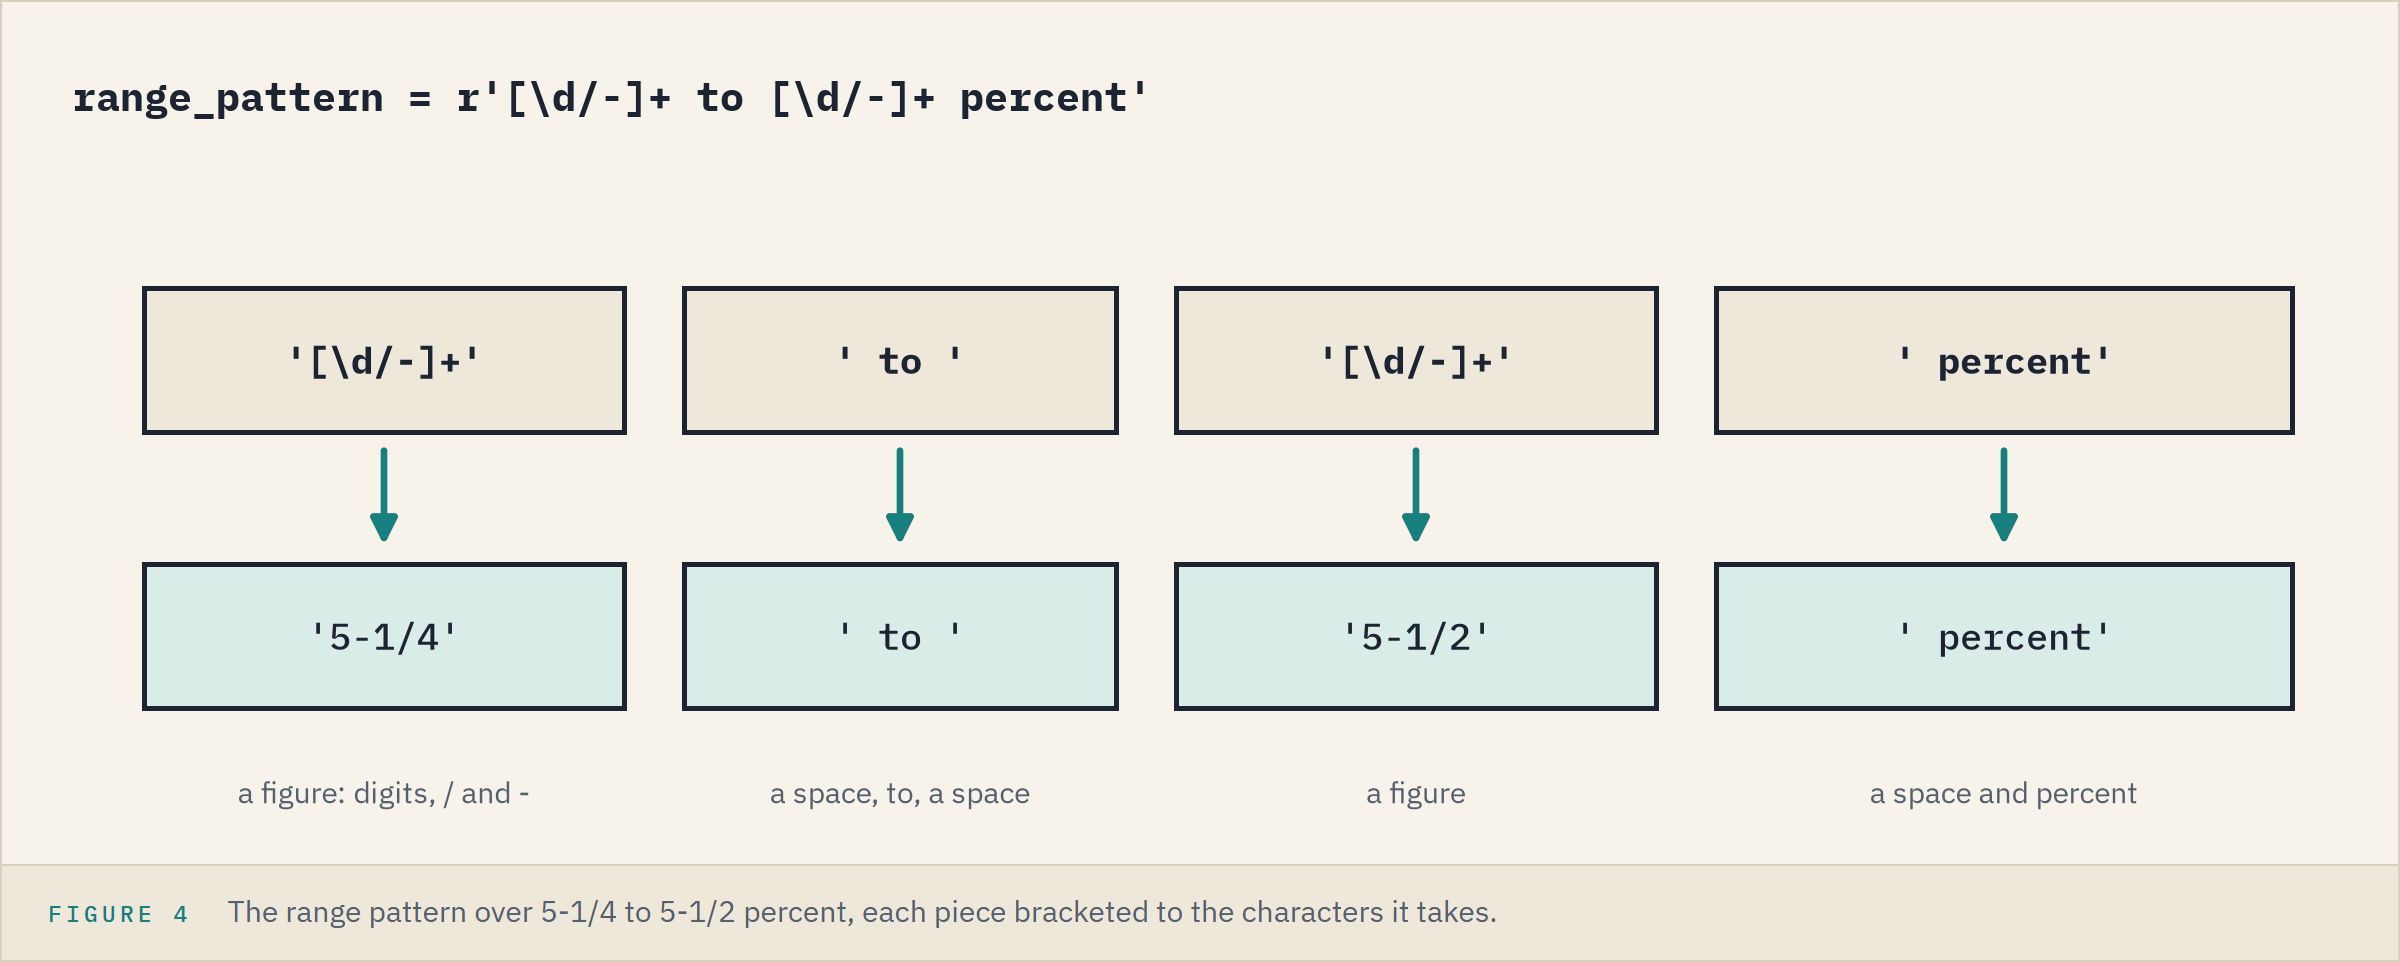

### Groups Pull Out the Ends

Q. Pull out the two ends of the range separately.

In [16]:
# round brackets mark a group; findall() then returns the groups
print(re.findall(r'([\d/-]+) to ([\d/-]+) percent', policy))
# search() returns the first match, which can be asked for its parts
match = re.search(r'([\d/-]+) to ([\d/-]+) percent', policy)
print(match.group(0), '|', match.group(1), '|', match.group(2), '|', match.start())

[('5-1/4', '5-1/2')]
5-1/4 to 5-1/2 percent | 5-1/4 | 5-1/2 | 218


`group(0)` is the whole match, `group(1)` and `group(2)` the bracketed pieces, starting at position 218.
The ends are text: `5-1/4` becomes 5.25 only by arithmetic.

Q. Put a marker where the range is.

In [17]:
# sub(): the pattern, the replacement, then the text
print(re.sub(range_pattern, '[RANGE]', policy_sentences[1]))

In support of these goals, the Committee decided to maintain the target range for the federal funds rate at [RANGE]


`re.sub()` is `replace()` with a pattern: it marks any range in this style, whatever its digits.

**The figures: 2 percent three times, and a range of 5-1/4 to 5-1/2 percent.**

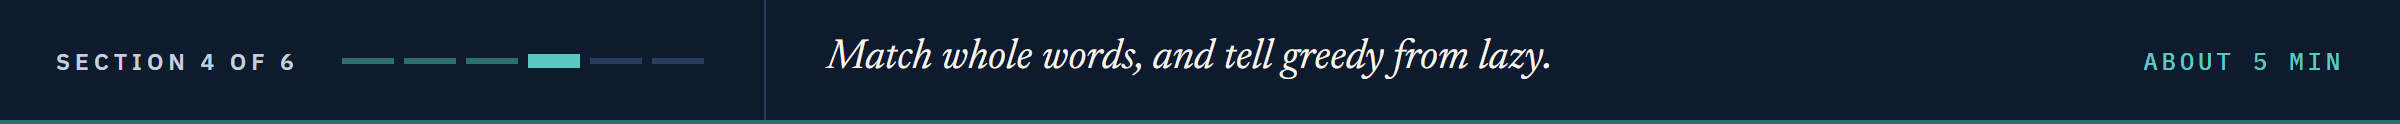

## 17.4 Whole Words, and How Much a Pattern Takes

### When Nothing Matches

Q. Search the paragraph for a figure in basis points.

In [18]:
# the first figure followed by the words basis points
re.search(r'\d+ basis points', policy).group(0)

AttributeError: 'NoneType' object has no attribute 'group'

Read the last line, as on Day 3: with no match, `search()` returns `None`, Python's value for nothing, and `None` has no `group()`.

Q. Search again, and handle the case of no match.

In [19]:
# keep the result in a name; is None is the test for no match
match = re.search(r'\d+ basis points', policy)
if match is None:
    print('No figure in basis points in this paragraph.')
else:
    print(match.group(0))

No figure in basis points in this paragraph.


### `rate` as a Whole Word

**Predict 3**

Q. `statement.count('rate')` returns 4 for the whole statement. What does `re.findall(r'\brate\b', statement)` return?

A) 4 matches, as `count()` does.
B) 3 matches.
C) No matches: the backslashes spoil the pattern.

In [20]:
# count() first, then two patterns
print(statement.count('rate'))
# \w is a letter, a digit, or an underscore; * is none or more of it
print(re.findall(r'\w*rate\w*', statement))
# \b is the edge of a word
print(re.findall(r'\brate\b', statement))

4
['moderated', 'rate', 'rate', 'rate']
['rate', 'rate', 'rate']


B: 3, and the middle line shows the fourth piece was `moderated`.
`\b` matches no character, only the place where a word starts or ends.

<table align="left">
<tr><th align="left">Piece</th><th align="left">Means</th></tr>
<tr><td align="left"><code>\w</code></td><td align="left">a letter, a digit, or an underscore</td></tr>
<tr><td align="left"><code>\b</code></td><td align="left">the edge of a word</td></tr>
<tr><td align="left"><code>*</code>, <code>?</code>, <code>{4}</code></td><td align="left">none or more; none or one; exactly 4</td></tr>
<tr><td align="left"><code>\s</code>, <code>\S</code></td><td align="left">a space, a tab, or a line break; any character that is not one</td></tr>
<tr><td align="left"><code>.</code></td><td align="left">any character but a line break; <code>\.</code> is a full stop</td></tr>
</table>
<br clear="left">

**The word rate appears 3 times; `count()` said 4.**

### Greedy and Lazy

`+` and `*` are **greedy**: they take as much text as they can.
A `?` straight after one makes it **lazy**: as little as it can.

Q. Take the text between ` at ` and ` percent` in the third paragraph, greedy and then lazy.

In [21]:
# greedy: .+ runs on to the last ' percent'
greedy = re.search(r' at (.+) percent', policy).group(1)
# lazy: .+? stops at the first ' percent' it reaches
lazy = re.search(r' at (.+?) percent', policy).group(1)
print(len(greedy), 'of', len(policy), 'characters')
print(lazy)
print(re.findall(r' at (.+?) percent', policy))

858 of 944 characters
the rate of 2
['the rate of 2', '5-1/4 to 5-1/2']


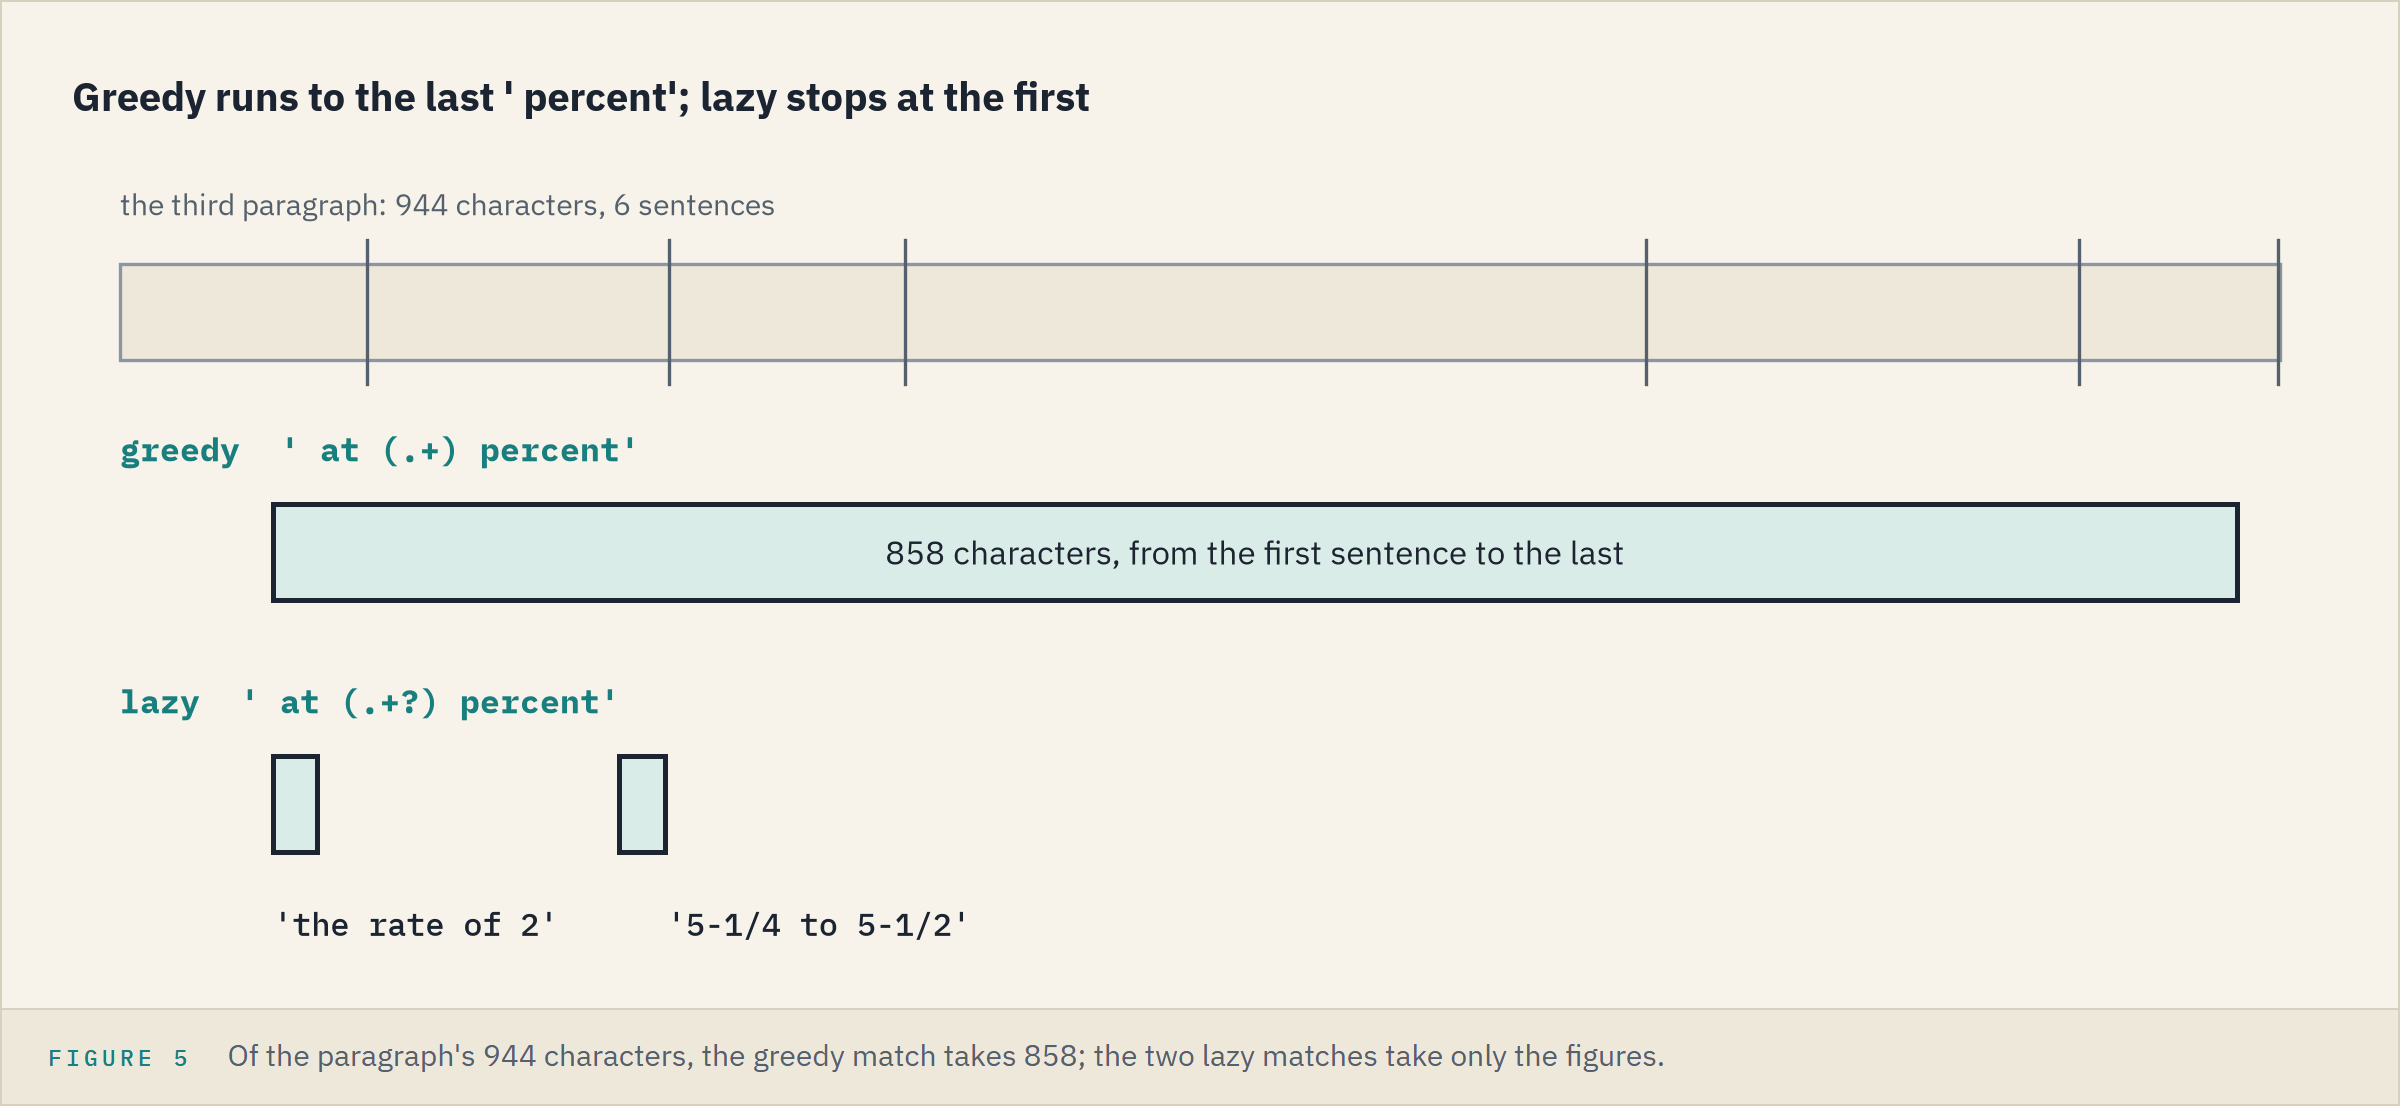

Greedy took 858 of the 944 characters, from the first sentence to the last; lazy took 13.

**The range pattern cannot run on like this: a letter is not in its brackets.**

> STORY: On July 2, 2019, Cloudflare deployed a new rule in its web application firewall. The critical part of its regular expression was `.*(?:.*=.*)`: three greedy runs around one equals sign. The matcher tried so many ways to fit them that the CPUs serving web traffic ran at nearly 100 percent, and the service went down for 27 minutes. Source: https://blog.cloudflare.com/details-of-the-cloudflare-outage-on-july-2-2019/

**Excel side by side.** The third paragraph in A2:

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">The first match</td><td align="left"><code>re.search(pattern, text).group(0)</code></td><td align="left"><code>=REGEXEXTRACT(A2, pattern)</code>: <code>5-1/4 to 5-1/2 percent</code></td></tr>
<tr><td align="left">Between two markers</td><td align="left"><code>re.search(r' at (.+?) percent', text).group(1)</code></td><td align="left"><code>=TEXTBEFORE(TEXTAFTER(A2, " at "), " percent")</code>: <code>the rate of 2</code>, the lazy answer</td></tr>
<tr><td align="left">Cells holding a piece</td><td align="left"><code>count()</code> on each word</td><td align="left"><code>=COUNTIF(B2:B38, "*rate*")</code> on the 37 words: 2</td></tr>
</table>
<br clear="left">

`REGEXEXTRACT` is in Microsoft 365 only; `TEXTBEFORE` and `TEXTAFTER` are in Microsoft 365 and Excel 2024; the `*` wildcard works in every version.
Flash Fill (Ctrl+E) copies a typed pattern, as values, not a formula.

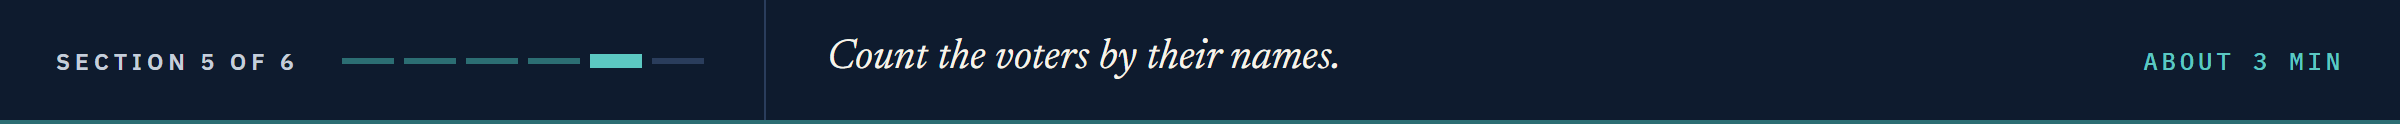

## 17.5 Who Voted

### First and Last Words

Q. Which word opens each paragraph, and which closes it?

In [22]:
# ^ ties a pattern to the start; re.MULTILINE makes that the start of every line
print(re.findall(r'^\w+', statement, re.MULTILINE))
# $ ties it to the end of a line; \. is a real full stop
print(re.findall(r'\w+\.$', statement, re.MULTILINE))

['Recent', 'The', 'The', 'In', 'Voting']
['elevated.', 'risks.', 'objective.', 'developments.', 'Waller.']


`^` and `$` are **anchors**: a pattern tied to the start or the end cannot match in the middle.

Q. How many names does the voting paragraph list, and how many does a name pattern find?

In [23]:
# the last paragraph, then its names counted two ways
voting = paragraphs[-1]
print(voting)
# semicolons separate the names: one name more than semicolons
print('By semicolons:', voting.count(';') + 1)
# a first name, a middle initial and full stop, a last name
strict = re.findall(r'[A-Z][a-z]+ [A-Z]\. [A-Z][a-z]+', voting)
print('By the pattern:', len(strict))

Voting for the monetary policy action were Jerome H. Powell, Chair; John C. Williams, Vice Chair; Michael S. Barr; Michelle W. Bowman; Lisa D. Cook; Austan D. Goolsbee; Patrick Harker; Philip N. Jefferson; Neel Kashkari; Adriana D. Kugler; Lorie K. Logan; and Christopher J. Waller.
By semicolons: 12
By the pattern: 10


The pattern found 10 of the 12: it **matched too little**, as Patrick Harker and Neel Kashkari have no middle initial, and it insists on one.

### The Initial Made Optional

Q. Make the middle initial optional, and drop the title.

In [24]:
# (?: ) groups without handing the group back; the ? after it makes it optional
loose = re.findall(r'[A-Z][a-z]+ (?:[A-Z]\. )?[A-Z][a-z]+', voting)
print(len(loose), loose[:3])
# keep every match but the title
names = [name for name in loose if name != 'Vice Chair']
print(len(names))

13 ['Jerome H. Powell', 'John C. Williams', 'Vice Chair']
12


13: `Vice Chair` starts each word with a capital, all the loose pattern asks; without it, 12.
Tighten a pattern and real names drop out; loosen it and false ones come in.

Q. Draw the three counts against the semicolons' count.

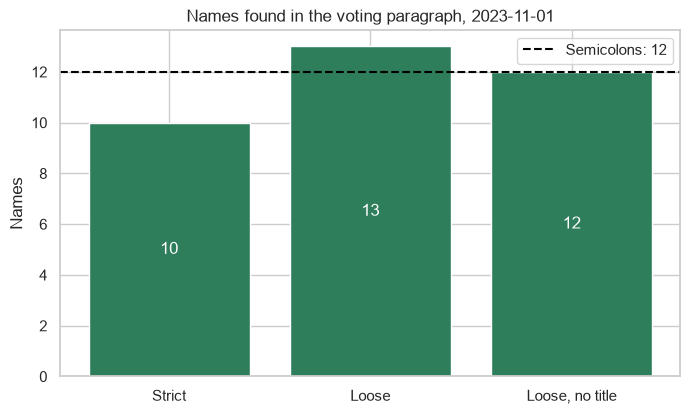

In [25]:
# one bar per pattern, and the semicolons' count as a dashed line
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(['Strict', 'Loose', 'Loose, no title'], [len(strict), len(loose), len(names)])
ax.bar_label(bars, label_type='center', color='white')
# pandas Part 1's axhline(): a line across at the count from the semicolons
ax.axhline(voting.count(';') + 1, color='black', linestyle='--', label='Semicolons: 12')
ax.set_title('Names found in the voting paragraph, 2023-11-01')
ax.set_ylabel('Names')
ax.legend()
plt.show()

**The count from the semicolons decided which way each pattern was wrong.**

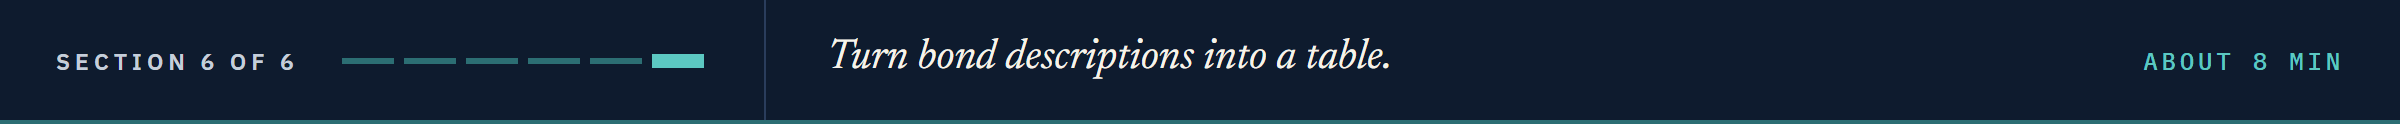

## 17.6 From the Statement to the Book

### A Whole Value

Anchors at both ends test a whole value, such as a date.

Q. Which of three values has the shape of a date? Does the page address agree with the `date` column?

In [26]:
# four digits, a hyphen, two digits, a hyphen, two digits, and nothing before or after
date_pattern = r'^\d{4}-\d{2}-\d{2}$'
for value in ['2023-11-01', '2023-11-1', '11/01/2023']:
    print(value, re.search(date_pattern, value) is not None)
url = statements.loc[statements['date'] == '2023-11-01', 'url'].iloc[0]
# the address holds the date as eight digits in a row; .groups() hands back every group
print(re.search(r'(\d{4})(\d{2})(\d{2})', url).groups())

2023-11-01 True
2023-11-1 False
11/01/2023 False
('2023', '11', '01')


The address agrees.
`2023-99-99` would pass too: Combining Part 2's `pd.to_datetime()` is the test of a real date.

### The Broker's Descriptions

Q. Read the ticker, the coupon, and the maturity out of the first description.

In [27]:
# eight descriptions typed from the holdings file: ticker, coupon in percent, maturity
descriptions = ['KRIX 7.875 08/26/2032', 'BEZE 7 06/18/2032', 'BEZH 8.125 04/17/2029',
                'BEZL 5.125 06/03/2030', 'LORE 7.25 03/08/2030', 'OSTV  6.5 04/01/2033',
                'SYLX 3.625 09/03/2055', 'VYRN 7.375 12/12/2037']
# three groups: capitals; digits, a full stop, digits; month/day/year
first_pattern = r'([A-Z]+) (\d+\.\d+) (\d{2}/\d{2}/\d{4})'
# re.fullmatch(): the pattern must cover the whole text, as ^ and $ at both ends would
print(re.fullmatch(first_pattern, descriptions[0]).groups())

('KRIX', '7.875', '08/26/2032')


Three pieces, all text, the coupon included.
`fullmatch()` is safer than `^` and `$`: `$` also matches just before a final line break, so `'2023-11-01\n'` would pass the date test above.

### Reading All Eight

**Predict 4**

Q. Look at the eight descriptions in the cell above. How many will `first_pattern` read? Write down a number.

In [28]:
# fullmatch() returns None for a description the pattern cannot read
not_read = [text for text in descriptions if re.fullmatch(first_pattern, text) is None]
print(len(descriptions) - len(not_read), not_read)

6 ['BEZE 7 06/18/2032', 'OSTV  6.5 04/01/2033']


6: `BEZE 7` has no decimal point, and `OSTV` has two spaces after it.
No error was raised: only the count, eight in and six read, said so.

### Widen It and Build the Table

Q. Widen the pattern, and build a table of the eight bonds.

In [29]:
# \s+ is one or more white-space characters; (?:\.\d+)? makes the decimals optional
description_pattern = r'([A-Z]+)\s+(\d+(?:\.\d+)?)\s+(\d{2}/\d{2}/\d{4})'
rows = []
for text in descriptions:
    match = re.fullmatch(description_pattern, text)
    # Day 3's assert: stop, and name the description, if one cannot be read
    assert match is not None, 'cannot read: ' + text
    ticker, coupon, maturity = match.groups()
    rows.append({'ticker': ticker, 'coupon': float(coupon), 'maturity': maturity})
bonds = pd.DataFrame(rows)

Q. Make the maturity a date. What are the mean coupon and the latest maturity?

In [30]:
# format= names the layout, as in Combining Part 2: %m month, %d day, %Y year
bonds['maturity'] = pd.to_datetime(bonds['maturity'], format='%m/%d/%Y')
print(bonds)
print(round(bonds['coupon'].mean(), 3), bonds['maturity'].max().date())

  ticker  coupon   maturity
0   KRIX   7.875 2032-08-26
1   BEZE   7.000 2032-06-18
2   BEZH   8.125 2029-04-17
3   BEZL   5.125 2030-06-03
4   LORE   7.250 2030-03-08
5   OSTV   6.500 2033-04-01
6   SYLX   3.625 2055-09-03
7   VYRN   7.375 2037-12-12
6.609 2055-09-03


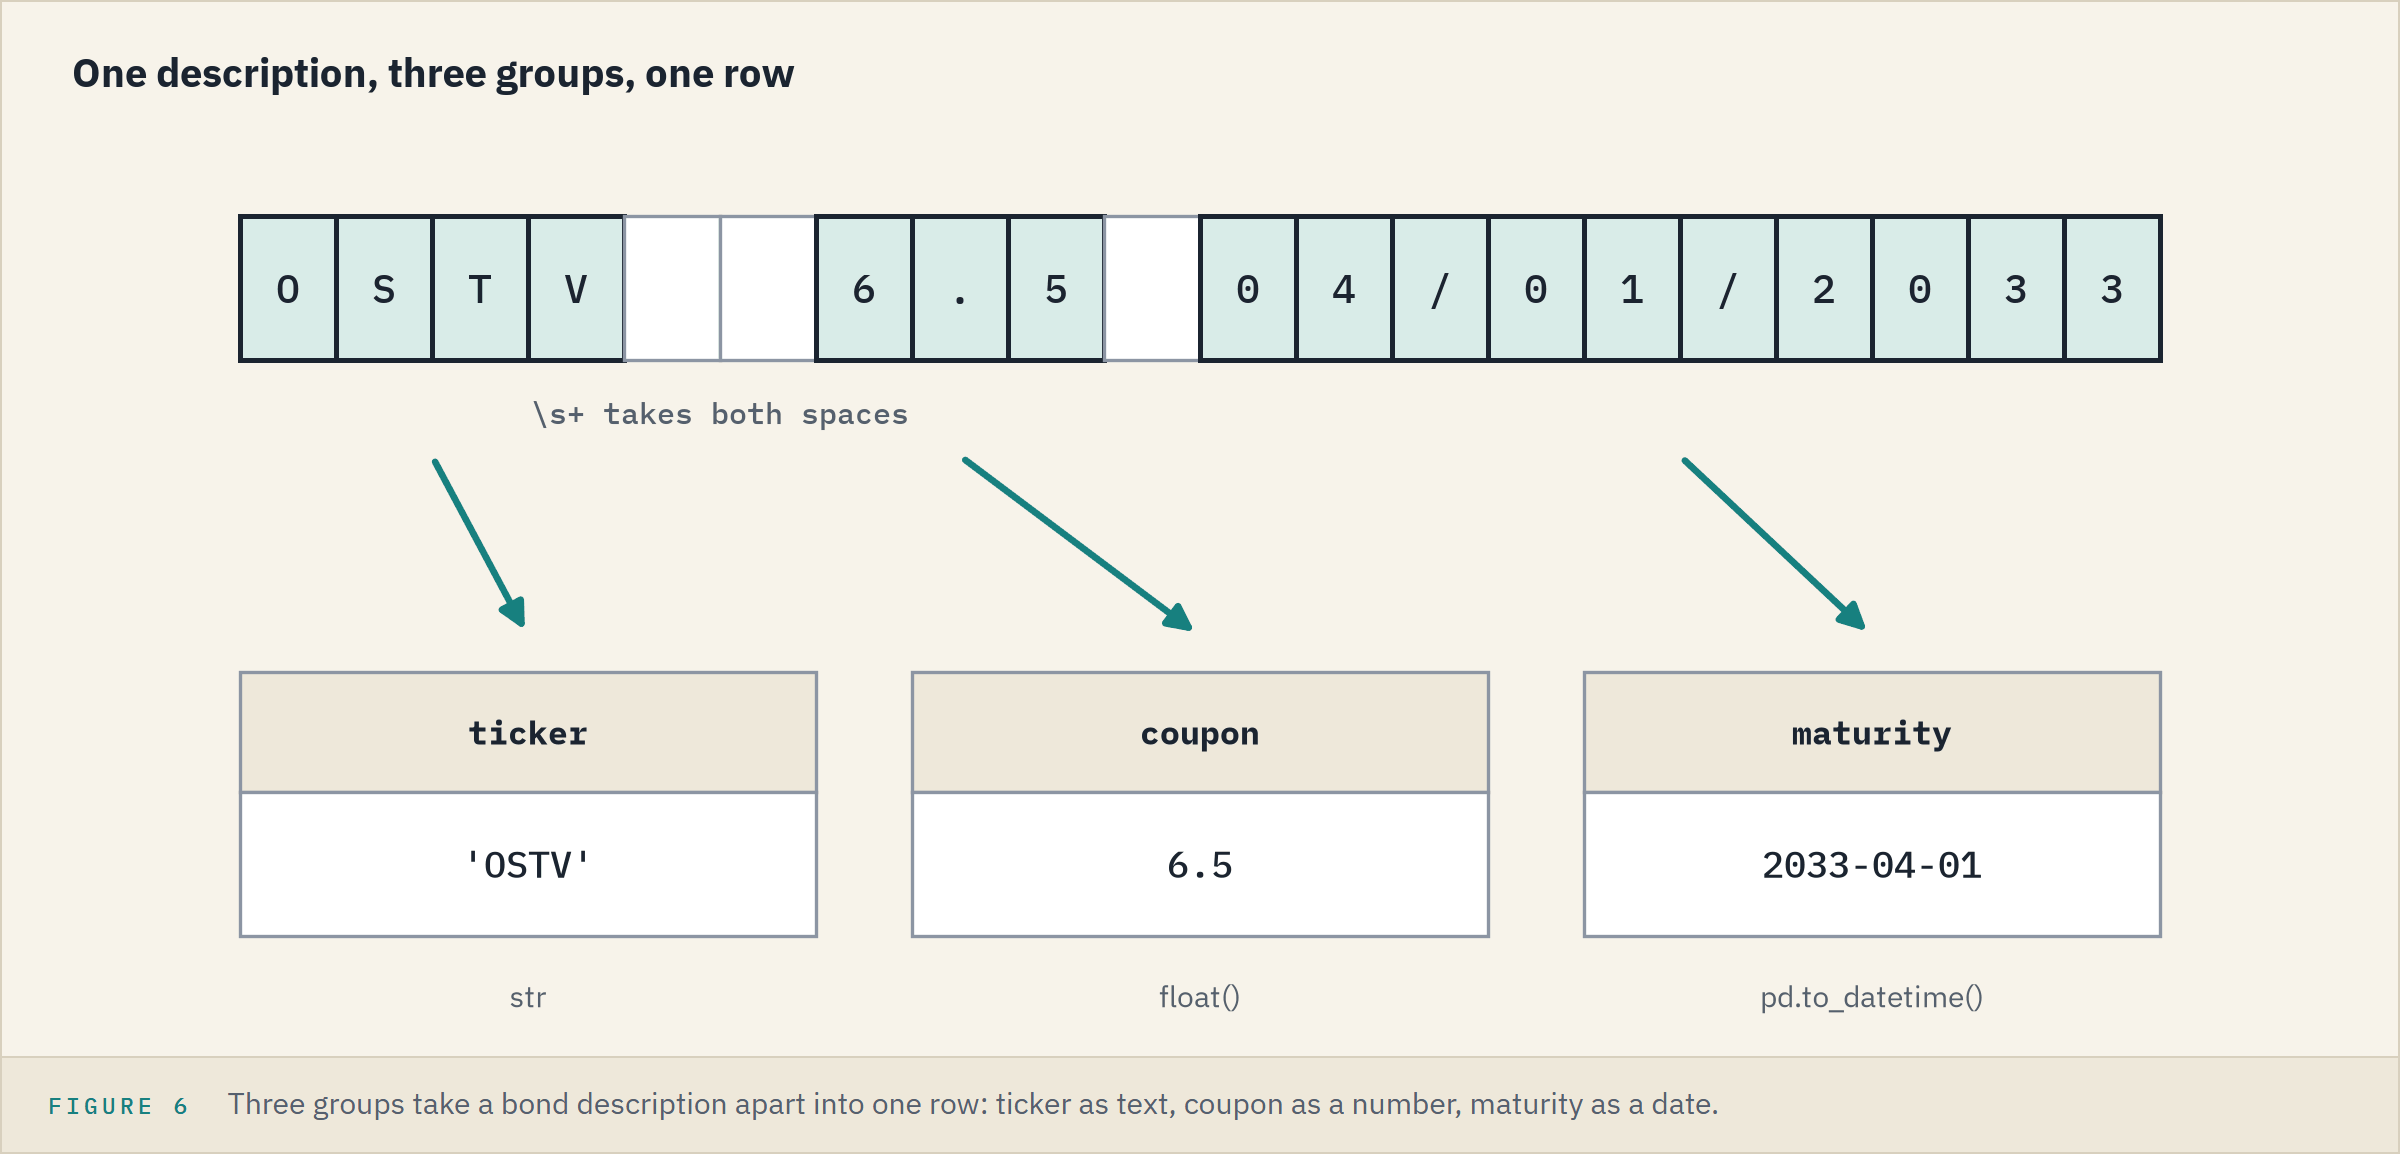

8 of 8: mean coupon 6.609 percent, latest maturity 2055-09-03.
A coupon written as a fraction would stop the `assert`, which names the text.

**Excel side by side.** `=TEXTSPLIT(TRIM(A2), " ")` in B2 spills the three pieces into B2:D2, `TRIM` squeezing the double space; `=VALUE(C2)` makes the coupon a number.
In Microsoft 365, `=REGEXEXTRACT(A2, pattern, 2)` gives one cell per group.

Q. Draw coupon against maturity, each point named.

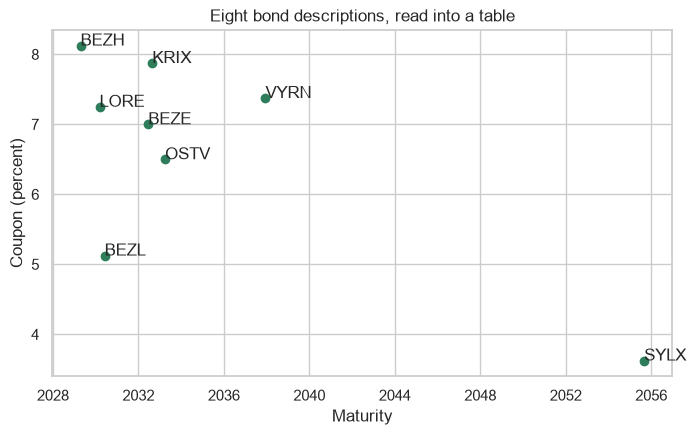

In [31]:
# one point per bond: maturity across, coupon up
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(bonds['maturity'], bonds['coupon'])
# annotate(), from the Visualization notebook: each ticker at its point
for ticker, maturity, coupon in zip(bonds['ticker'], bonds['maturity'], bonds['coupon']):
    ax.annotate(ticker, (maturity, coupon))
ax.set_title('Eight bond descriptions, read into a table')
ax.set_xlabel('Maturity')
ax.set_ylabel('Coupon (percent)')
plt.show()

SYLX, 3.625 percent in 2055, sits alone on the right; BEZH, 8.125 percent, is the highest coupon.

**Eight lines of text became a table.**

### Every CUSIP in the Book

A CUSIP is Day 1's nine boxes, here each a digit or a capital.

Q. Does every CUSIP in the holdings file have that shape?

In [32]:
# dtype= keeps the identifier as text, as in Combining Part 2
cusips = pd.read_csv(data_folder + 'holdings.csv', dtype={'cusip': str})['cusip']
# [0-9A-Z], not \d: \d also matches the digits of other writing systems
cusip_shape = r'[0-9A-Z]{9}'
# .str runs a text method on every value, as in the EDA notebook
has_shape = cusips.str.fullmatch(cusip_shape)
print(len(cusips), has_shape.sum())
assert has_shape.all(), 'a CUSIP without the shape'

200 200


Q. Test the first CUSIP and four damaged copies of it.

In [33]:
# the first CUSIP, then copies in lower case, one short, with a space, with a hyphen
for value in [cusips.iloc[0], '99080cae8', '99080CAE', '99080CAE8 ', '99080-CAE8']:
    print(repr(value), re.fullmatch(cusip_shape, value) is not None)

'99080CAE8' True
'99080cae8' False
'99080CAE' False
'99080CAE8 ' False
'99080-CAE8' False


Each copy fails, and `repr()` shows the trailing space the eye misses.

### Repair a Damaged Copy

Q. Remove every character that cannot be in a CUSIP.

In [34]:
# [^0-9A-Z] is any character that is not a digit or a capital; sub() swaps each for nothing
repaired = re.sub(r'[^0-9A-Z]', '', '99080-CAE8 ')
print(repr(repaired), re.fullmatch(cusip_shape, repaired) is not None)
print(re.sub(r'[^0-9A-Z]', '', '99080cae8'))

'99080CAE8' True
990808


The hyphen and the space go, and the copy passes; the lower-case copy shrinks to `990808`, the wrong repair.

**Excel side by side.** `=REGEXTEST(B2, "^[0-9A-Z]{9}$")` in Microsoft 365, anchored because it searches; in every version, `=LEN(B2)=9` and `=EXACT(B2, UPPER(B2))` test the length and the capitals.

**200 of 200 have the shape; the ninth character, a check digit, is a test for another day.**

## You Can Now

By the end of this notebook, you can:

* Measure, search, count, split, join, and strip text.
* Build a regex from `\d`, `\w`, `\s`, `\b`, classes, `+`, `*`, `?`, anchors, and groups.
* Use `re.findall()`, `re.search()`, and `re.sub()`, and tie a pattern to an outside count.
* Tell greedy from lazy, and test a whole value with `re.fullmatch()`.
* Read bond descriptions into a table and test every CUSIP's shape.

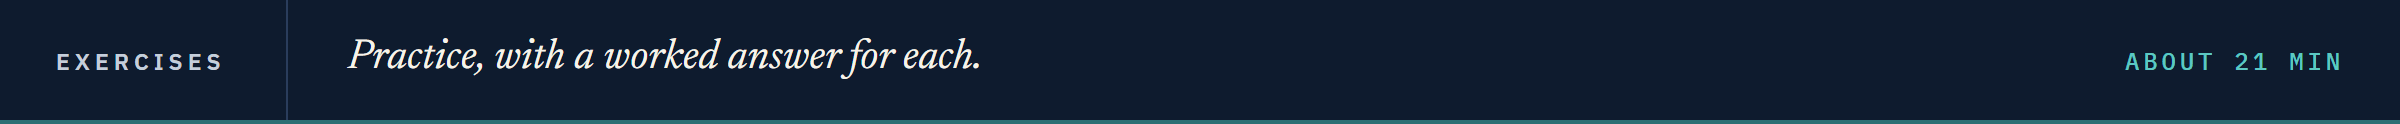

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Exercises 1 and 2 use the statement of 2022-09-21, `other`; the rest use text typed from the holdings file.
Replace each `...` with your own code, then run the check cell under it.
Run the next two cells first: the first defines `check`, which marks your answers; the second loads the statements.

In [35]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [36]:
import os
import re

import pandas as pd

# a fresh copy of the statements; in Colab, from GitHub
if os.path.exists('../../../data/fomc_statements.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
statements = pd.read_csv(data_folder + 'fomc_statements.csv')
# the statement of Exercises 1 and 2
other = statements.loc[statements['date'] == '2022-09-21', 'text'].iloc[0]
print(statements.shape, type(other))

(46, 3) <class 'str'>


### Exercise 1

Q. For `other`, store the characters in **ex1_characters**, the words by `split()` in **ex1_words**, and the count of `inflation`, capitals ignored, in **ex1_inflation**.

In [37]:
ex1_characters = ...
ex1_words = ...
ex1_inflation = ...

In [38]:
check('Exercise 1 characters', ex1_characters, 2066)
check('Exercise 1 words', ex1_words, 314)
check('Exercise 1 inflation', ex1_inflation, 7)

Exercise 1 characters: not attempted yet
Exercise 1 words: not attempted yet
Exercise 1 inflation: not attempted yet


### Exercise 2

Q. In `other`, store the `re.findall()` list for the range `... to ... percent` in **ex2_range**, its upper end as a number in **ex2_upper** (`3-1/4` is 3.25), and the number of names in the last paragraph in **ex2_names**.

In [39]:
ex2_range = ...
ex2_upper = ...
ex2_names = ...

In [40]:
check('Exercise 2 range', ex2_range, ['3 to 3-1/4 percent'])
check('Exercise 2 upper end', ex2_upper, 3.25)
check('Exercise 2 names', ex2_names, 12)

Exercise 2 range: not attempted yet
Exercise 2 upper end: not attempted yet
Exercise 2 names: not attempted yet


### Exercise 3

Run the next cell: six descriptions, and nine identifiers, some damaged on purpose.

In [41]:
# six descriptions, typed by hand: ticker, coupon in percent, maturity as month/day/year
more_descriptions = ['KRIX 6.625 05/09/2033', 'BEZL 6.125 04/09/2053',
                     'ZEPN 5 08/16/2036', 'GALX  9.25 06/17/2038',
                     'TROE 4.375 12/26/2027', 'LORE 8.625 06/09/2032']
# nine identifiers, typed by hand
identifiers = ['99087JAG1', '99039NAG1', '99138IAF4', '99088kah5', '99093PAA',
               '99114KAB6 ', '99053-BAG8', '99057FAC4', '99005FAA1']
print(len(more_descriptions), len(identifiers))

6 9


Q. With a group, read each description's coupon as a number: store the six, in order, in **ex3_coupons**, and the highest in **ex3_highest**. Look at the descriptions first.

In [42]:
ex3_coupons = ...
ex3_highest = ...

In [43]:
check('Exercise 3 coupons', ex3_coupons, [6.625, 6.125, 5.0, 9.25, 4.375, 8.625])
check('Exercise 3 highest coupon', ex3_highest, 9.25)

Exercise 3 coupons: not attempted yet
Exercise 3 highest coupon: not attempted yet


### Exercise 4

Q. Turn the six maturities into dates with `format='%m/%d/%Y'`: store the latest one's year in **ex4_latest_year** and the number after 2030-12-31 in **ex4_after_2030**.

In [44]:
ex4_latest_year = ...
ex4_after_2030 = ...

In [45]:
check('Exercise 4 latest year', ex4_latest_year, 2053)
check('Exercise 4 maturing after 2030', ex4_after_2030, 5)

Exercise 4 latest year: not attempted yet
Exercise 4 maturing after 2030: not attempted yet


### Exercise 5

Q. Test the nine `identifiers` against a CUSIP's shape: store the number that pass in **ex5_valid** and the failures, in order, in **ex5_failed**, printed with `repr()`.

In [46]:
ex5_valid = ...
ex5_failed = ...

In [47]:
check('Exercise 5 with the shape', ex5_valid, 5)
check('Exercise 5 failures', ex5_failed, ['99088kah5', '99093PAA', '99114KAB6 ', '99053-BAG8'])

Exercise 5 with the shape: not attempted yet
Exercise 5 failures: not attempted yet


### Exercise 6

Q. Write `parse_description(text)`, which returns a dictionary: `'ticker'` as text, `'coupon'` as a number, `'maturity'` as the date text. It must read every description in Exercise 3.

In [48]:
def parse_description(text):
    """Return the ticker, the coupon as a number, and the maturity text of one description."""
    return ...

In [49]:
check('Exercise 6 plain description', parse_description('KRIX 6.625 05/09/2033'),
      {'ticker': 'KRIX', 'coupon': 6.625, 'maturity': '05/09/2033'})
check('Exercise 6 whole-number coupon', parse_description('ZEPN 5 08/16/2036'),
      {'ticker': 'ZEPN', 'coupon': 5.0, 'maturity': '08/16/2036'})
check('Exercise 6 two spaces', parse_description('GALX  9.25 06/17/2038'),
      {'ticker': 'GALX', 'coupon': 9.25, 'maturity': '06/17/2038'})

Exercise 6 plain description: not attempted yet
Exercise 6 whole-number coupon: not attempted yet
Exercise 6 two spaces: not attempted yet


### Exercise 7: AI check

An AI assistant gives you this code for the mean coupon of the lesson's eight descriptions.
It was written for this course in the style of an AI answer, and has one bug.

Q. The lesson found 6.609 percent. Read the code first: what will it print?

In [50]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
descriptions = ['KRIX 7.875 08/26/2032', 'BEZE 7 06/18/2032', 'BEZH 8.125 04/17/2029',
                'BEZL 5.125 06/03/2030', 'LORE 7.25 03/08/2030', 'OSTV  6.5 04/01/2033',
                'SYLX 3.625 09/03/2055', 'VYRN 7.375 12/12/2037']

# the coupon is the first number in each description
ex7_coupons = [float(re.search(r'\d+', text).group(0)) for text in descriptions]
ex7_mean = round(sum(ex7_coupons) / len(ex7_coupons), 3)

print(ex7_coupons)
print('Mean coupon:', ex7_mean, 'percent')

[7.0, 7.0, 8.0, 5.0, 7.0, 6.0, 3.0, 7.0]
Mean coupon: 6.25 percent


Q. Find the bug and fix the cell above, so that **ex7_coupons** and **ex7_mean** hold the right values.

In [51]:
check('Exercise 7 coupons', ex7_coupons, [7.875, 7.0, 8.125, 5.125, 7.25, 6.5, 3.625, 7.375])
check('Exercise 7 mean coupon', ex7_mean, 6.609)

Exercise 7 coupons: not yet. You have [7.0, 7.0, 8.0, 5.0, 7.0, 6.0, 3.0, 7.0]
Exercise 7 mean coupon: not yet. You have 6.25


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">The figures</td><td align="left"><code>2 percent</code> three times, and <code>5-1/4 to 5-1/2 percent</code></td></tr>
<tr><td align="left">Rate, the word</td><td align="left">3 times; <code>count()</code> said 4</td></tr>
<tr><td align="left">Who voted</td><td align="left">12 names, as the semicolons say</td></tr>
<tr><td align="left">The descriptions as a table</td><td align="left">8 of 8, mean coupon 6.609 percent</td></tr>
<tr><td align="left">Every CUSIP's shape</td><td align="left">200 of 200</td></tr>
</table>
<br clear="left">

Be proud of the quiet catch: a count of 4 looked right until the printed matches showed the tail of `5-1/2 percent`.
Printing what matched, and tying it to an outside count, makes a text count worth sending.

Part 2 cleans the text, counts its words, and runs the same work on all 46 statements.

[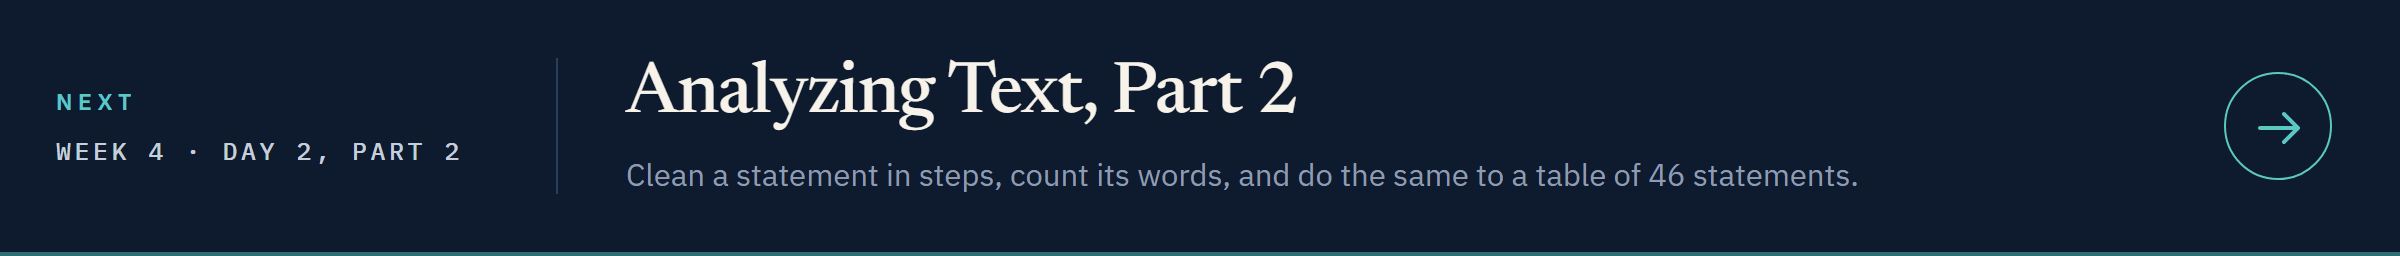](../day2_part2/17_part2_analyzing_text.ipynb)

[Open Day 2, Part 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day2_part2/17_part2_analyzing_text.ipynb)